# Litho stochastics, flare and focus blur

The lithography notebooks so far computed one image and one resist profile:
the average over infinitely many photons and molecules, in one focal plane,
through a perfectly clean lens. A real exposure differs from that average in
three ways that this notebook adds to `pyoptics.litho`:

- **Stochastics** (`litho.stochastics`). A 45 nm line at ArF receives a few
  hundred photons per nm² and its resist holds a few acid generator and
  quencher molecules per nm² column. Their counts are random, and the
  edges of a printed line become rough: line edge roughness (LER), line
  width roughness (LWR), the spread of contact hole sizes (local CD
  uniformity) and, at low dose, holes that do not open at all. The chain of
  notebook 35 (resist and swing curves) is run again with counts: Poisson
  photons, discrete acid and quencher in the post-exposure bake, discrete
  protecting groups.
- **Flare** (`litho.flare`). Roughness of the lens surfaces scatters a small
  fraction of the light into a halo reaching micrometres to millimetres. It
  adds a background that depends on how much of the mask around a feature is
  clear.
- **Focus blur** (`litho.focus_blur`). The laser line has a bandwidth, the
  lens has axial colour, and the stage vibrates: every point is exposed in a
  spread of focal planes and blurred sideways.

All three keep the wavelength (and with it the photon energy and the
scatter, which grow as $1/\lambda$ and $1/\lambda^2$) as a parameter, so
that the EUV notebooks that follow can reuse them with $\lambda$ = 13.5 nm.
Earlier notebooks used here: notebook 31 (vectorial imaging in lithography)
for the images, notebook 35 (resist and swing curves) for the resist chain,
notebook 33 (lens aberrations across the slit) for Caldwell's KrF lens and
notebook 148 (detectors and photon statistics) for Poisson statistics.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import sketch
from pyoptics.litho import (Illumination, LithoSimulation, MaskLayout, Projector, ThinMask, flare,
                            focus_blur, lens, metrics, resist, stochastics as st)
from pyoptics.raytrace import caldwell_krf_lens

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()
BLUE, ORANGE, GREEN, YELLOW, RED, PURPLE, GREY = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#d03b3b",
                                                  "#8a5cc2", "#888888")

## 1. Counting photons and molecules

A dose $D$ in mJ/cm² is $10^{-17} D$ J/nm², and a photon carries $E_\mathrm{ph} = hc/\lambda$:

| | KrF 248 nm | ArF 193 nm | EUV 13.5 nm |
|---|---|---|---|
| photon energy | 5.0 eV | 6.4 eV | 92 eV |
| photons per nm² per mJ/cm² | 12.5 | 9.7 | 0.68 |

At the same dose EUV delivers 14 times fewer photons than ArF. Only a part
of them is absorbed in the resist (here a 90 nm ArF resist with $\alpha$ =
1/µm absorbs 8.6 %), and only some of the absorbed ones turn an acid
generator (PAG) molecule into acid. `StochasticResist` follows the chain of
`resist.ResistModel` on a top-down grid where each cell is a column through
the resist:

1. absorbed photons per cell: Poisson with the mean $\bar n$ from the image,
2. acids: on average $\rho_\mathrm{PAG} V\,(1 - e^{-C D I})$ per cell
   (Dill $C$ as in notebook 35, resist and swing curves), which makes
   $y$ acids per absorbed photon on average, the acid yield. Given $n$
   photons the count is binomial, $\mathrm{Bin}(n, y)$, for $y \le 1$ (one
   acid at most per photon, KrF and ArF) and Poisson with the mean $y n$ for
   $y > 1$ (several acids per photon from the secondary electrons of an EUV
   photon),
3. quencher: Poisson with the mean $q\,\rho_\mathrm{PAG} V$,
4. the bake of `ResistModel.bake()` (diffusion, neutralization,
   amplification) starting from these counts,
5. protected groups: Poisson with the mean $\rho_b V m$,
6. development: the protected fraction blurred over 2 nm, cleared where
   $m < m_\mathrm{th}$.

The sketches show the counting and what is measured afterwards.

{'C': 0.05, 'diffusion_length': 10.0, 'amplification': 3.0, 'quencher': 0.15, 'quencher_diffusion_length': 5.0, 'neutralization': None, 'r_max': 100.0, 'r_min': 0.1, 'n': 5.0, 'm_th': 0.5, 'develop_time': 60.0, 'n_steps': 20}
KrF:   5.0 eV, 12.50 photons/nm^2 per mJ/cm^2
ArF:   6.4 eV,  9.73 photons/nm^2 per mJ/cm^2
EUV:  91.8 eV,  0.68 photons/nm^2 per mJ/cm^2

ArF at 30.0 mJ/cm^2: 25.1 absorbed photons per nm^2, 6.3 PAG and 0.95 quencher per nm^2 column
within 4 pi sigma^2 = 1257 nm^2 (sigma = 10.0 nm): 31585 photons, 6150 acids at full dose
acid yield: 0.19 acids per absorbed photon in the open frame, 0.38 at low intensity


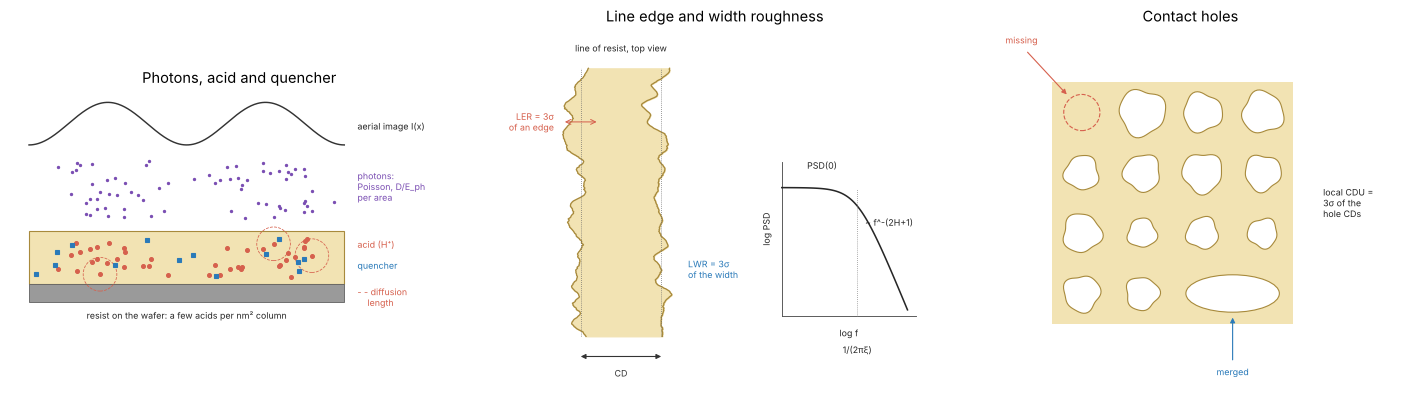

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sketch.litho_stochastics_layout(axes[0], "shot_noise", title="Photons, acid and quencher")
sketch.litho_stochastics_layout(axes[1], "roughness", title="Line edge and width roughness")
sketch.litho_stochastics_layout(axes[2], "contacts", title="Contact holes")
fig.tight_layout()

R = st.StochasticResist()   # ArF defaults: 90 nm, alpha 1/um, 0.07 PAG/nm^3, quencher 0.15
print(R.model.__dict__)
for name, lam in (("KrF", 248.3), ("ArF", 193.368), ("EUV", 13.5)):
    print(f"{name}: {st.photon_energy(lam)/1.602176634e-19:5.1f} eV, "
          f"{st.photons_per_area(1.0, lam):5.2f} photons/nm^2 per mJ/cm^2")
D = 30.0
area = 4*np.pi*R.model.diffusion_length**2      # the area one acid explores in the bake
print(f"\nArF at {D} mJ/cm^2: {R.absorbed_photons(D):.1f} absorbed photons per nm^2, "
      f"{R.pag*R.thickness:.1f} PAG and {R.model.quencher*R.pag*R.thickness:.2f} quencher per nm^2 column")
print(f"within 4 pi sigma^2 = {area:.0f} nm^2 (sigma = {R.model.diffusion_length} nm): "
      f"{R.absorbed_photons(D, area):.0f} photons, "
      f"{R.pag*R.thickness*area*(1 - np.exp(-R.model.C*D)):.0f} acids at full dose")
print(f"acid yield: {R.acid_yield(1.0, D, 1.0):.2f} acids per absorbed photon in the open frame, "
      f"{R.acid_yield(0.0, D, 1.0):.2f} at low intensity")

## 2. Rough lines at ArF

45 nm lines and spaces (pitch 90 nm) with water immersion (NA 1.35), a
y-polarized dipole and a binary mask, sized to 45 nm with the mean chain.
A strip 2 µm long shows the edges. The mean chain gives straight edges; with
counts the edges wander by a few nanometres.

NILS 2.94, dose to size 28.2 mJ/cm^2


Roughness(cd=44.85, ler=2.44, lwr=3.52, correlation=-0.04, broken=0.000)


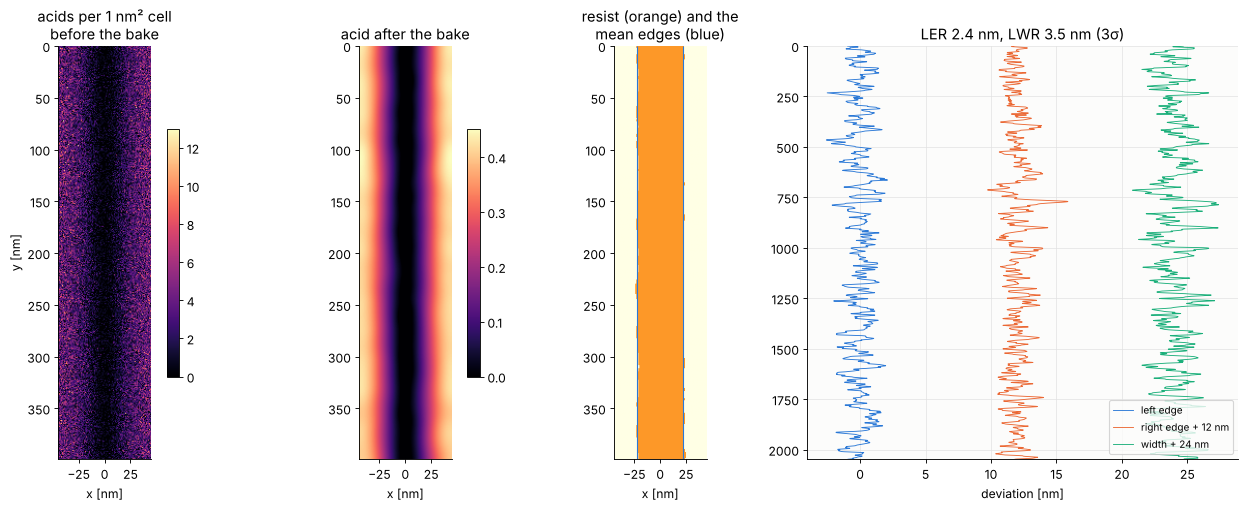

In [3]:
proj = Projector(1.35, 193.368, n=1.437)
lines = LithoSimulation(MaskLayout.lines_spaces(90.0, 45.0), ThinMask.binary(),
                        Illumination.dipole(0.9, 0.7, n_samples=15, polarization="y"), proj)
dx = 1.0
x = np.arange(-45.0, 45.0, dx)            # one period, centred on the line
y = np.arange(0.0, 2048.0, dx)
I_line = lines.image(x)
D_line = R.dose_to_size(x, I_line, 45.0)
I2 = np.tile(I_line, (len(y), 1))
print(f"NILS {lines.nils(threshold=0.3):.2f}, dose to size {D_line:.1f} mJ/cm^2")

res = R.process(I2, D_line, dx, rng=1)
mean = R.mean(I2, D_line, dx)
left, right = st.line_edges(x, res.m, R.model.m_th)
rough = st.roughness(left, right)
print(rough)

fig, axes = plt.subplots(1, 4, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 1, 1, 1.4]})
show = slice(0, 400)
ext = (x[0], x[-1] + dx, y[show][-1], y[0])
im = axes[0].imshow(res.acid_0[show], extent=ext, aspect="equal", cmap="magma")
axes[0].set_title("acids per 1 nm² cell\nbefore the bake")
fig.colorbar(im, ax=axes[0], shrink=0.6)
im = axes[1].imshow(res.acid[show], extent=ext, aspect="equal", cmap="magma")
axes[1].set_title("acid after the bake")
fig.colorbar(im, ax=axes[1], shrink=0.6)
axes[2].imshow(res.m[show] >= R.model.m_th, extent=ext, aspect="equal", cmap="YlOrBr", vmax=2)
axes[2].contour(x, y[show], mean.m[show], [R.model.m_th], colors=[BLUE], linewidths=1.0)
axes[2].set_title("resist (orange) and the\nmean edges (blue)")
for ax in axes[:3]:
    ax.set_xlabel("x [nm]"); ax.grid(False)
axes[0].set_ylabel("y [nm]")
ax = axes[3]
ax.plot(left - np.nanmean(left), y, color=BLUE, lw=0.8, label="left edge")
ax.plot(right - np.nanmean(right) + 12, y, color=ORANGE, lw=0.8, label="right edge + 12 nm")
ax.plot(right - left - np.nanmean(right - left) + 24, y, color=GREEN, lw=0.8, label="width + 24 nm")
ax.set_ylim(y[-1], 0); ax.set_xlabel("deviation [nm]"); ax.legend(fontsize=9, loc="lower right")
ax.set_title(f"LER {rough.ler:.1f} nm, LWR {rough.lwr:.1f} nm (3σ)")
fig.tight_layout()

Each cell of 1 nm² holds only a few acids before the bake (left): the shot
noise is huge on that scale. The bake spreads each acid over a diffusion
length of 10 nm and averages hundreds of them, which smooths the acid (second
panel) and leaves a roughness of a few nanometres at the edges. Because both
edges see independent noise, the width varies more than one edge: LWR is
about $\sqrt{2}$ LER when the edges are uncorrelated.

### Where the roughness comes from

Switching the noise sources on one at a time shows their shares.

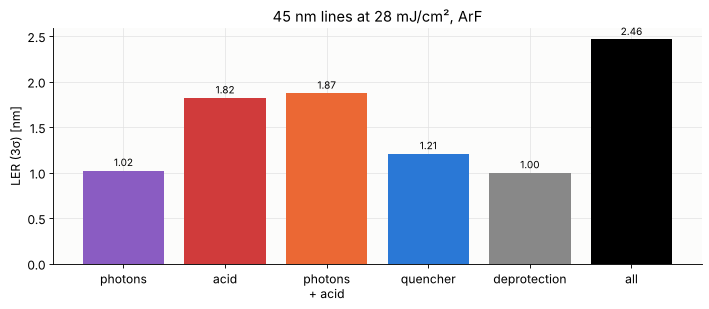

In [4]:
sources = [("photon",), ("acid",), ("photon", "acid"), ("quencher",), ("deprotection",), st.NOISE_SOURCES]
labels = ["photons", "acid", "photons\n+ acid", "quencher", "deprotection", "all"]
seeds = range(4)
ler = []
for src in sources:
    Rs = R.with_(noise=src)
    ler.append(np.mean([st.roughness(*st.line_edges(x, Rs.process(I2, D_line, dx, rng=s).m,
                                                     R.model.m_th)).ler for s in seeds]))
ler = np.array(ler)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(labels, ler, color=[PURPLE, RED, ORANGE, BLUE, GREY, "k"])
ax.set_ylabel("LER (3σ) [nm]")
ax.set_title(f"45 nm lines at {D_line:.0f} mJ/cm², ArF")
for i, v in enumerate(ler):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=9)
fig.tight_layout()

At ArF the acid count is the largest source. The photons alone contribute
less, and photons and acid together give the same roughness as the acid
alone: the acids are a random subset of the absorbed photons (yield $y$ of
about 0.3), and a random subset of a Poisson number is again Poisson. What
counts is the number of acids, not the number of photons. The photon
noise on its own has only $y$ times the variance of the acid count. The
quencher adds its own noise where it neutralizes the acid at the edge, the
protecting groups add a little more, and the variances of these
independent sources add up.

## 3. Dose, wavelength and the photon limit

The classic trade-off: a higher dose means more photons and less noise. To
change the photon count without changing the mean chain, the dose $D$ goes
up while Dill $C$ goes down ($C D$ fixed): the mean resist image and the
mean acid count stay the same, only the acid yield per photon changes. The
same chemistry is then exposed with 13.5 nm photons, 14 times fewer at the
same dose, in a film that absorbs 4/µm instead of 1/µm (EUV resists are
made more absorbing to catch more photons). At low doses an EUV photon has
to make several acids.

ArF acid yield: 0.54, 0.27, 0.13, 0.07, 0.03


EUV photons acid yield: 2.20, 1.10, 0.55, 0.28, 0.14


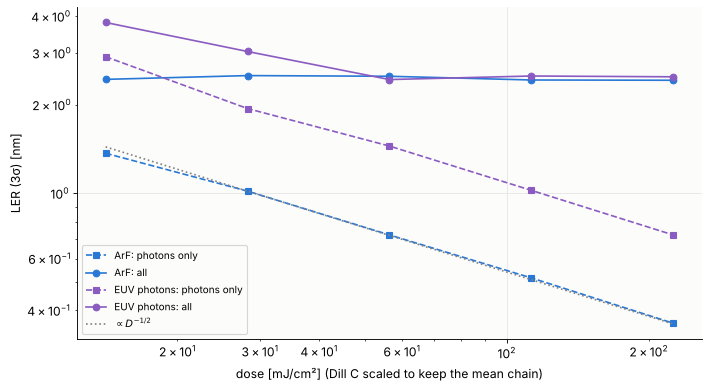

In [5]:
factors = np.array([0.5, 1.0, 2.0, 4.0, 8.0])
I_s = I2[:1024]
out = {}
for name, lam, alpha in (("ArF", 193.368, 1e-3), ("EUV photons", 13.5, 4e-3)):
    Rw = R.with_(wavelength=lam, absorption=alpha)
    print(name, "acid yield:", ", ".join(f"{Rw.with_(model=R.model.with_(C=R.model.C/f)).acid_yield(0.5, f*D_line, dx):.2f}"
                                       for f in factors))
    for noise, tag in ((("photon",), "photons only"), (st.NOISE_SOURCES, "all")):
        vals = []
        for f in factors:
            Rf = Rw.with_(noise=noise, model=R.model.with_(C=R.model.C/f))
            vals.append(np.mean([st.roughness(*st.line_edges(x, Rf.process(I_s, f*D_line, dx, rng=s).m,
                                                              R.model.m_th)).ler for s in range(3)]))
        out[name, tag] = np.array(vals)
fig, ax = plt.subplots(figsize=(9, 5))
for (name, tag), v in out.items():
    ax.loglog(factors*D_line, v, "o-" if tag == "all" else "s--", color=BLUE if name == "ArF" else PURPLE,
              label=f"{name}: {tag}")
ref = out["ArF", "photons only"]
ax.loglog(factors*D_line, ref[1]*np.sqrt(factors[1]/factors), ":", color="0.5", label=r"$\propto D^{-1/2}$")
ax.set_xlabel("dose [mJ/cm²] (Dill C scaled to keep the mean chain)")
ax.set_ylabel("LER (3σ) [nm]")
ax.legend(fontsize=9)
fig.tight_layout()

The photon part alone follows $D^{-1/2}$, the Poisson law. At ArF the total
does not move: the acid count is fixed, and the photons only decide which
acid generator molecules react. A higher dose helps only together with a
chemistry that makes more acids (more PAG, a higher quantum yield). With
13.5 nm photons the photon noise is several times larger, and as long as
each photon has to make more than one acid ($y > 1$) the acid count
fluctuates more than a Poisson count, by the factor $1 + y$ in variance. The
EUV resist reaches the ArF floor only at a dose where it makes fewer acids
than it absorbs photons. This is why EUV resists run at high doses and why
stochastics dominate EUV (the EUV notebooks take this up with a real EUV
image).

## 4. The power spectrum of the edges

LER is a single number; the power spectral density (PSD) of the edge
deviation $\delta x(y)$ says on which length scales the edges wander. The usual
model has a flat part at low frequencies and a power law above $1/(2\pi\xi)$:

$$\mathrm{PSD}(f) = \frac{\mathrm{PSD}(0)}{\left(1 + (2\pi f \xi)^2\right)^{H + 1/2}},$$

with the correlation length $\xi$ and the roughness exponent $H$, and
$\sigma^2 = \int_0^\infty \mathrm{PSD}\,df$. The acid diffusion length sets
$\xi$: a longer bake smooths the short wavelengths, but it also lowers the
slope of the deprotection at the edge, which turns the remaining noise
into larger edge excursions. The fits use the frequencies below 0.1/nm;
above, the 2 nm development blur cuts the spectrum off faster than the
model.

diffusion length, dose to size, LER, xi, H, |dm/dx| at the edge
     3 nm   27.4 mJ/cm^2   4.91 nm    3.2 nm  1.00  0.0280/nm
     5 nm   27.6 mJ/cm^2   3.71 nm    5.3 nm  1.00  0.0276/nm
    10 nm   28.2 mJ/cm^2   2.39 nm    6.6 nm  0.95  0.0251/nm
    15 nm   28.6 mJ/cm^2   2.05 nm   13.4 nm  0.38  0.0219/nm
    20 nm   29.1 mJ/cm^2   2.09 nm   22.6 nm  0.16  0.0186/nm
    30 nm   29.7 mJ/cm^2   2.70 nm   20.4 nm  0.05  0.0121/nm


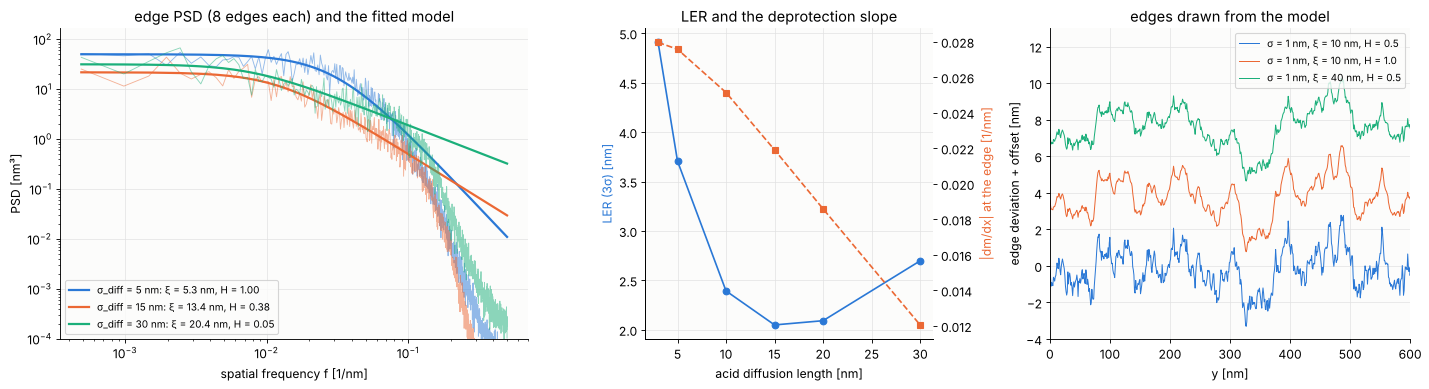

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1.3, 0.8, 1]})
summary = []
colors = {5.0: BLUE, 15.0: ORANGE, 30.0: GREEN}
for sigma_d in (3.0, 5.0, 10.0, 15.0, 20.0, 30.0):
    Rd = R.with_(model=R.model.with_(diffusion_length=sigma_d))
    Dd = Rd.dose_to_size(x, I_line, 45.0)
    left_d, right_d = [], []
    for s in range(4):
        l, r = st.line_edges(x, Rd.process(I2, Dd, dx, rng=10 + s).m, R.model.m_th)
        left_d.append(l); right_d.append(r)
    f, p = st.edge_psd(y, np.array(left_d + right_d))
    sig, xi, H = st.fit_psd(f, p, f_max=0.1)
    ler_d = st.roughness(np.array(left_d), np.array(right_d)).ler
    m_mean = Rd.mean(I_line[None, :], Dd, dx).m[0]
    slope = np.abs(np.interp(-22.5, x[:-1] + dx/2, np.diff(m_mean)/dx))
    summary.append((sigma_d, Dd, ler_d, xi, H, slope))
    if sigma_d in colors:
        col = colors[sigma_d]
        axes[0].loglog(f, p, color=col, lw=0.8, alpha=0.5)
        axes[0].loglog(f, st.psd_model(f, sig, xi, H), color=col, lw=2,
                       label=f"σ_diff = {sigma_d:.0f} nm: ξ = {xi:.1f} nm, H = {H:.2f}")
axes[0].set_ylim(1e-4, None)
axes[0].set_xlabel("spatial frequency f [1/nm]"); axes[0].set_ylabel("PSD [nm³]")
axes[0].legend(fontsize=9, loc="lower left"); axes[0].set_title("edge PSD (8 edges each) and the fitted model")
summary = np.array(summary)
ax = axes[1]
ax.plot(summary[:, 0], summary[:, 2], "o-", color=BLUE)
ax.set_xlabel("acid diffusion length [nm]"); ax.set_ylabel("LER (3σ) [nm]", color=BLUE)
ax2 = ax.twinx()
ax2.plot(summary[:, 0], summary[:, 5], "s--", color=ORANGE)
ax2.set_ylabel("|dm/dx| at the edge [1/nm]", color=ORANGE); ax2.grid(False)
ax.set_title("LER and the deprotection slope")
for k, (H, col) in enumerate(((0.5, BLUE), (1.0, ORANGE))):
    e = st.random_edges(len(y), dx, 1.0, 10.0, H, n_edges=1, rng=3)[0]
    axes[2].plot(y, e + 4*k, color=col, lw=0.9, label=f"σ = 1 nm, ξ = 10 nm, H = {H}")
e = st.random_edges(len(y), dx, 1.0, 40.0, 0.5, n_edges=1, rng=3)[0]
axes[2].plot(y, e + 8, color=GREEN, lw=0.9, label="σ = 1 nm, ξ = 40 nm, H = 0.5")
axes[2].set_xlim(0, 600); axes[2].set_ylim(-4, 13); axes[2].set_xlabel("y [nm]")
axes[2].set_ylabel("edge deviation + offset [nm]")
axes[2].legend(fontsize=9, loc="upper right"); axes[2].set_title("edges drawn from the model")
fig.tight_layout()
print("diffusion length, dose to size, LER, xi, H, |dm/dx| at the edge")
for row in summary:
    print("  {:4.0f} nm  {:5.1f} mJ/cm^2  {:5.2f} nm  {:5.1f} nm  {:4.2f}  {:.4f}/nm".format(*row))

The fitted correlation length grows with the diffusion length, from 3 nm to
about 20 nm, while the slope of the spectrum above the knee flattens (the
exponent $H$ falls). Short diffusion keeps the deprotection slope at the
edge steep but averages few acids, so the edges are rough on short scales.
Long diffusion averages many acids, but it flattens the slope, and the
edges wander slowly over long distances. The LER has a minimum in between,
here at about 15 nm. This is one face of the resolution, LER and
sensitivity trade-off: none of the three improves without paying in
another.

## 5. Contact holes: local CD uniformity and missing holes

A clip of 12 × 12 contact holes, 65 nm at a pitch of 130 nm, attenuated
phase shift mask, quasar illumination, sized to 60 nm. `contact_stats()`
measures every hole (equivalent diameter of the cleared area), counts holes
that do not open and holes that merge with a neighbour, and gives the local
CD uniformity (LCDU, 3σ of the hole CDs).

dose to size 54.2 mJ/cm^2


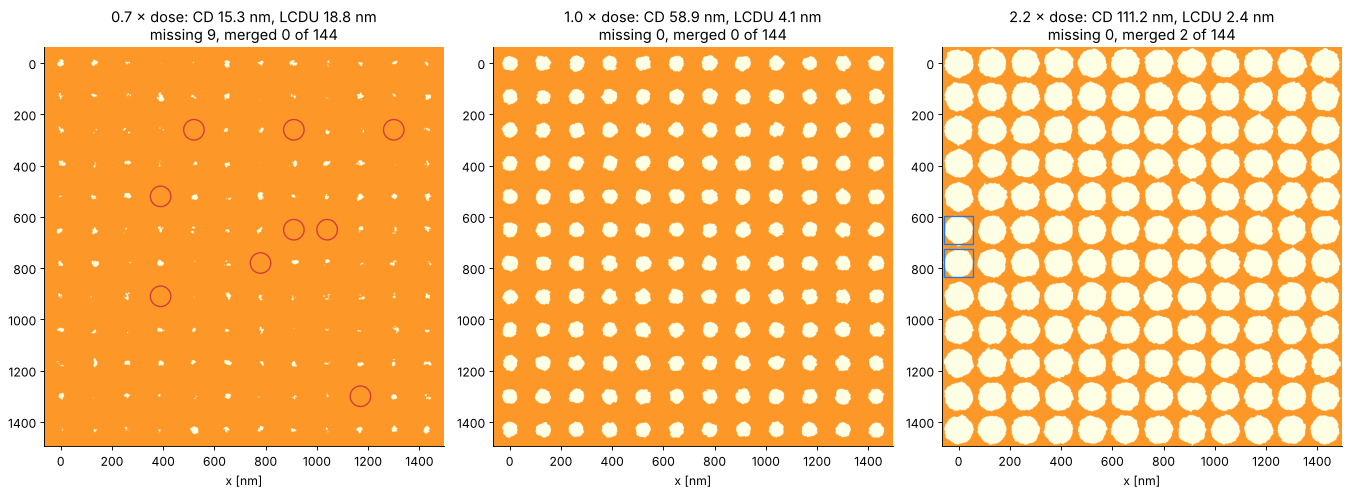

In [7]:
p_c = 130.0
contacts = LithoSimulation(MaskLayout.contact_holes(p_c, 65.0), ThinMask.att_psm(),
                           Illumination.quasar(0.9, 0.6, n_samples=15), proj)
dxc = 2.0
n_c = 12
xc = np.arange(-p_c/2, -p_c/2 + n_c*p_c, dxc)
I_c = contacts.image(xc, xc)
n_p = int(p_c/dxc)
D_c = R.dose_to_size(xc[:n_p], I_c[n_p//2, :n_p], 60.0, feature="space")
print(f"dose to size {D_c:.1f} mJ/cm^2")

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, f in zip(axes, (0.7, 1.0, 2.2)):
    r = R.process(I_c, f*D_c, dxc, rng=1)
    s = st.contact_stats(xc, xc, r.cleared, p_c)
    ax.imshow(~r.cleared, extent=(xc[0], xc[-1] + dxc, xc[-1] + dxc, xc[0]), cmap="YlOrBr", vmax=2)
    for (j, i) in zip(*np.nonzero(s.missing)):
        ax.add_patch(plt.Circle((i*p_c, j*p_c), 40, fill=False, ec=RED, lw=1.2))
    for (j, i) in zip(*np.nonzero(s.merged)):
        ax.add_patch(plt.Rectangle((i*p_c - 55, j*p_c - 55), 110, 110, fill=False, ec=BLUE, lw=1.2))
    ax.set_title(f"{f:.1f} × dose: CD {s.mean_cd:.1f} nm, LCDU {s.lcdu:.1f} nm\n"
                 f"missing {s.missing.sum()}, merged {s.merged.sum()} of {s.n}")
    ax.grid(False); ax.set_xlabel("x [nm]")
fig.tight_layout()

At the nominal dose every hole opens, with a spread of a few nanometres. At
70 % of the dose the weakest holes no longer clear: the hole is not just
smaller, it is missing, because a hole opens only where the deprotection
crosses the threshold, and a downward fluctuation of the few acids in the
hole closes it entirely. At a high dose neighbouring holes start to merge
through the thin resist between them. A sweep over the dose with several
clips per dose:

5616 holes in 27 s


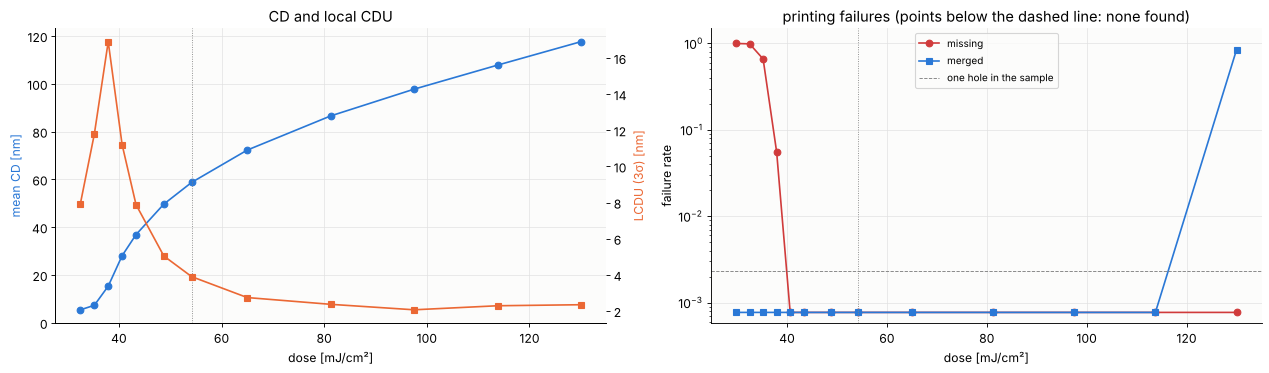

In [8]:
fs = np.array([0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9, 1.0, 1.2, 1.5, 1.8, 2.1, 2.4])
stats = []
t0 = time.time()
for f in fs:
    ss = [st.contact_stats(xc, xc, R.process(I_c, f*D_c, dxc, rng=100 + k).cleared, p_c) for k in range(3)]
    cd = np.concatenate([s.cd[s.good] for s in ss])
    stats.append((np.mean([s.missing_rate for s in ss]), np.mean([s.merged_rate for s in ss]),
                  np.mean(cd) if len(cd) else np.nan, 3*np.std(cd) if len(cd) > 1 else np.nan))
stats = np.array(stats)
print(f"{len(fs)*3*n_c**2} holes in {time.time() - t0:.0f} s")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
ax = axes[0]
ax.plot(fs*D_c, stats[:, 2], "o-", color=BLUE, label="mean CD")
ax.set_xlabel("dose [mJ/cm²]"); ax.set_ylabel("mean CD [nm]", color=BLUE)
ax2 = ax.twinx()
ax2.plot(fs*D_c, stats[:, 3], "s-", color=ORANGE)
ax2.set_ylabel("LCDU (3σ) [nm]", color=ORANGE); ax2.grid(False)
ax.axvline(D_c, color="0.5", lw=0.8, ls=":")
ax.set_title("CD and local CDU")
ax = axes[1]
floor = 1/(3*n_c**2)
ax.semilogy(fs*D_c, np.maximum(stats[:, 0], floor/3), "o-", color=RED, label="missing")
ax.semilogy(fs*D_c, np.maximum(stats[:, 1], floor/3), "s-", color=BLUE, label="merged")
ax.axhline(floor, color="0.5", lw=0.8, ls="--", label="one hole in the sample")
ax.set_ylim(floor/4, 1.5); ax.set_xlabel("dose [mJ/cm²]"); ax.set_ylabel("failure rate")
ax.axvline(D_c, color="0.5", lw=0.8, ls=":")
ax.legend(fontsize=9); ax.set_title("printing failures (points below the dashed line: none found)")
fig.tight_layout()

The local CDU grows as the dose drops (fewer molecules, flatter
deprotection), and below about 75 % of the nominal dose holes start to go
missing, with a rate that rises by decades within a few mJ/cm². On the other
side the holes merge at about 2.4 times the dose. Between the two cliffs lies the
stochastic process window. A chip has billions of holes, so the rates that
matter are 10⁻¹⁰ and below, far beyond any direct simulation: in practice
the tails of the CD distribution are measured and extrapolated, and they are
fatter than a Gaussian fit to the centre would say (De Bisschop).

## 6. Flare from lens roughness

Every surface with an RMS roughness $\sigma$ scatters the fraction
$\mathrm{TIS} = (2\pi(n-1)\sigma/\lambda)^2$ (a lens surface) or
$(4\pi\sigma/\lambda)^2$ (a mirror) out of the image. A surface spatial
frequency $f$ scatters by the angle $\lambda f$, which lands at
$r = \lambda f L$ on the wafer ($L$ the lever arm of the surface). The
roughness PSD of the surface therefore becomes the flare PSF,
`Flare.from_roughness()`; a fractal PSD gives a power law.

0.1 nm RMS: TIS 0.00033 % per fused silica surface at 193 nm, 0.87 % per mirror at 13.5 nm
DUV, 40 surfaces: Flare(total=0.0001324, r_min=3.87e+03, r_max=3.87e+06) 
EUV, 6 mirrors:   Flare(total=0.05199, r_min=270, r_max=2.7e+05)


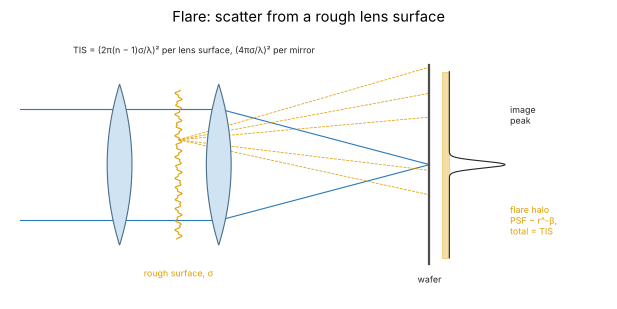

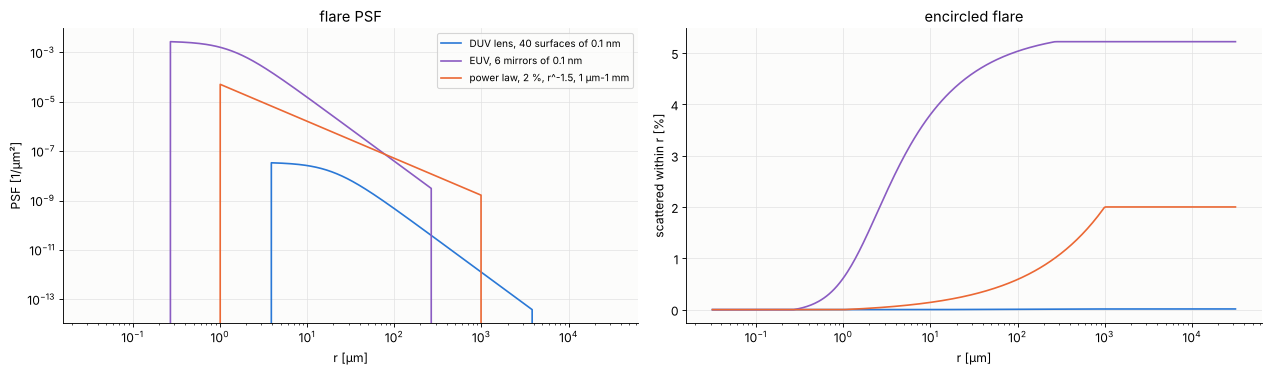

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
sketch.litho_stochastics_layout(ax, "flare", title="Flare: scatter from a rough lens surface")
fig.tight_layout()

# mid spatial frequency roughness, periods from 1 um to 1 mm, in nm units
psd = flare.ABCRoughness(sigma=0.1, B=2e5, C=1.6, f_min=1e-6, f_max=1e-3)
L_arm = 2e7      # 20 mm lever arm (nm)
duv = flare.Flare.from_roughness(psd, 193.368, L_arm, n=1.56, n_surfaces=40)
euv = flare.Flare.from_roughness(psd, 13.5, L_arm, n_surfaces=6)
budget = flare.Flare.power_law(0.02, 1.5, 1e3, 1e6)
print(f"0.1 nm RMS: TIS {100*flare.tis(0.1, 193.368, 1.56):.5f} % per fused silica surface at 193 nm, "
      f"{100*flare.tis(0.1, 13.5):.2f} % per mirror at 13.5 nm")
print("DUV, 40 surfaces:", duv, "\nEUV, 6 mirrors:  ", euv)

r = np.logspace(1.5, 7.5, 400)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for F, lab, col in ((duv, "DUV lens, 40 surfaces of 0.1 nm", BLUE), (euv, "EUV, 6 mirrors of 0.1 nm", PURPLE),
                    (budget, "power law, 2 %, r^-1.5, 1 µm-1 mm", ORANGE)):
    axes[0].loglog(r/1e3, F.psf(r)*1e6, color=col, label=lab)
    axes[1].semilogx(r/1e3, 100*F.encircled(r), color=col, label=lab)
axes[0].set_xlabel("r [µm]"); axes[0].set_ylabel("PSF [1/µm²]"); axes[0].legend(fontsize=9)
axes[1].set_xlabel("r [µm]"); axes[1].set_ylabel("scattered within r [%]")
axes[0].set_title("flare PSF"); axes[1].set_title("encircled flare")
fig.tight_layout()

The same roughness (0.1 nm RMS in the band from 1/mm to 1/µm) that scatters
a negligible 0.01 % in the 40 surfaces of a DUV lens scatters about 5 % from
six EUV mirrors: the factor is
$(2\cdot 193/(13.5\cdot 0.56))^2 \approx 2600$ per surface. The flare of real
DUV lenses, around 1 to 2 %, also comes from coatings, bulk scatter and
ghosts; for the image it is described the same way, as a power-law PSF and a
total, here 2 % with $r^{-1.5}$ between 1 µm and 1 mm.

The PSF reaches far beyond one clip, so its convolution with the clip is
constant: a background equal to the total times the pattern density, the
open fraction of the mask around the feature, weighted with the PSF. It
lowers the contrast and changes the dose to size.

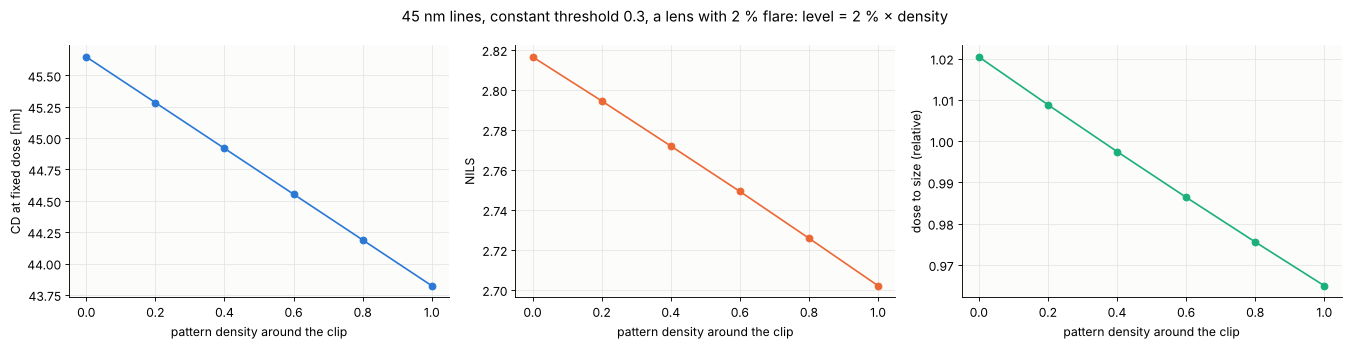

In [10]:
x_l = np.arange(-45.0, 45.0, 0.5)
I_l = lines.image(x_l)
dose = metrics.dose_to_size(x_l, I_l, 45.0, threshold=0.3)   # constant threshold model, no flare
densities = np.linspace(0, 1, 6)
cds, nils, doses = [], [], []
for lev in budget.level(densities):
    I_f = budget.apply(I_l, lev)
    cds.append(metrics.threshold_cd(x_l, dose*I_f, 0.3))
    nils.append(metrics.nils_at_threshold(x_l, dose*I_f, 0.3))
    doses.append(metrics.dose_to_size(x_l, I_f, 45.0, threshold=0.3))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
axes[0].plot(densities, cds, "o-", color=BLUE); axes[0].set_ylabel("CD at fixed dose [nm]")
axes[1].plot(densities, nils, "o-", color=ORANGE); axes[1].set_ylabel("NILS")
axes[2].plot(densities, np.array(doses)/dose, "o-", color=GREEN); axes[2].set_ylabel("dose to size (relative)")
for ax in axes:
    ax.set_xlabel("pattern density around the clip")
fig.suptitle("45 nm lines, constant threshold 0.3, a lens with 2 % flare: level = 2 % × density")
fig.tight_layout()

Each percent of flare level takes about a nanometre off the space (the
lines get thinner, here dark lines printed in a positive resist) and lowers
the NILS by a few percent. Since the flare level is the lens total times the
local pattern density, the same line prints differently in a dense block
and next to a large open area. A die of 26 × 33 mm with a dark periphery,
two memory blocks (density 0.5), a logic block (0.3) and a large clear
area (density 1, e.g. a scribe line or an alignment window):

flare level from 0.05 to 2.00 %, CD from 43.83 to 45.61 nm
  memory centre                   flare 1.00 %, CD 44.74 nm
  logic centre                    flare 0.60 %, CD 45.10 nm
  logic, 0.5 mm from the window   flare 0.56 %, CD 45.14 nm
  dark gap next to the window     flare 0.10 %, CD 45.56 nm
  periphery                       flare 0.10 %, CD 45.56 nm


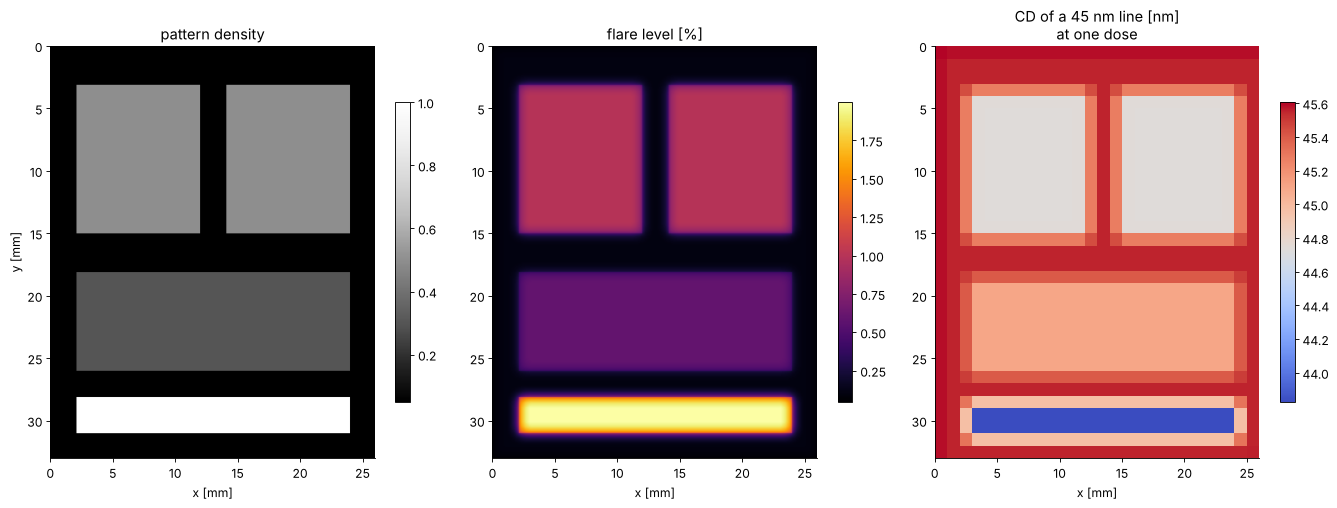

In [11]:
dxd = 0.1e6                                   # 100 um cells (nm)
Xd, Yd = np.meshgrid(np.arange(0, 26e6, dxd), np.arange(0, 33e6, dxd))
density = np.full(Xd.shape, 0.05)
density[(Xd > 2e6) & (Xd < 12e6) & (Yd > 3e6) & (Yd < 15e6)] = 0.5   # memory
density[(Xd > 14e6) & (Xd < 24e6) & (Yd > 3e6) & (Yd < 15e6)] = 0.5  # memory
density[(Xd > 2e6) & (Xd < 24e6) & (Yd > 18e6) & (Yd < 26e6)] = 0.3  # logic
density[(Xd > 2e6) & (Xd < 24e6) & (Yd > 28e6) & (Yd < 31e6)] = 1.0  # clear window
level = budget.level_map(density, dxd)
cd_map = np.array([[metrics.threshold_cd(x_l, dose*budget.apply(I_l, lv), 0.3) for lv in row[::10]]
                   for row in level[::10]])
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
ext = (0, 26, 33, 0)
im = axes[0].imshow(density, extent=ext, cmap="Greys_r"); axes[0].set_title("pattern density")
fig.colorbar(im, ax=axes[0], shrink=0.7)
im = axes[1].imshow(100*level, extent=ext, cmap="inferno"); axes[1].set_title("flare level [%]")
fig.colorbar(im, ax=axes[1], shrink=0.7)
im = axes[2].imshow(cd_map, extent=ext, cmap="coolwarm"); axes[2].set_title("CD of a 45 nm line [nm]\nat one dose")
fig.colorbar(im, ax=axes[2], shrink=0.7)
for ax in axes:
    ax.set_xlabel("x [mm]"); ax.grid(False)
axes[0].set_ylabel("y [mm]")
fig.tight_layout()
print(f"flare level from {100*level.min():.2f} to {100*level.max():.2f} %, "
      f"CD from {np.nanmin(cd_map):.2f} to {np.nanmax(cd_map):.2f} nm")
for name, (xm, ym) in {"memory centre": (7, 9), "logic centre": (13, 22), "logic, 0.5 mm from the window": (13, 25.5),
                       "dark gap next to the window": (13, 27), "periphery": (13, 1)}.items():
    lv = level[int(ym*1e6/dxd), int(xm*1e6/dxd)]
    print(f"  {name:31s} flare {100*lv:4.2f} %, CD {metrics.threshold_cd(x_l, dose*budget.apply(I_l, lv), 0.3):.2f} nm")

The flare level follows the density blurred over the range of the PSF: 1 %
in the memory blocks, 0.6 % in the logic block, 0.1 % in the dark
periphery and up to 2 % in the clear window. The same 45 nm line prints
almost a nanometre narrower in the memory than in the periphery, from flare
alone; in the clear window itself the level reaches the full 2 %. OPC corrects this with a flare map of
the die, a long-range density convolution like this one (Schellenberg et
al. for EUV, where the effect is several times larger).

## 7. Focus blur: laser bandwidth and axial colour

Both projection lenses that come with the ray tracer are made of fused
silica only and are not corrected for colour: their focus moves with the
wavelength. `lens.axial_colour()` takes the paraxial image distance at two
wavelengths from `System.with_wavelength()`: Caldwell's KrF lens (notebook
33, lens aberrations across the slit) and the Zeiss water immersion ArF lens
of the patent US 7,187,503.

axial colour: Caldwell KrF lens 241 nm per pm, Zeiss ArFi lens 306 nm per pm
  FWHM 0.15 pm: ArFi focus FWHM 46 nm, E95 1.9 pm (Lorentzian) / 0.25 pm (Gaussian)
  FWHM 0.3 pm: ArFi focus FWHM 92 nm, E95 3.8 pm (Lorentzian) / 0.50 pm (Gaussian)
  FWHM 0.6 pm: ArFi focus FWHM 184 nm, E95 7.6 pm (Lorentzian) / 1.00 pm (Gaussian)


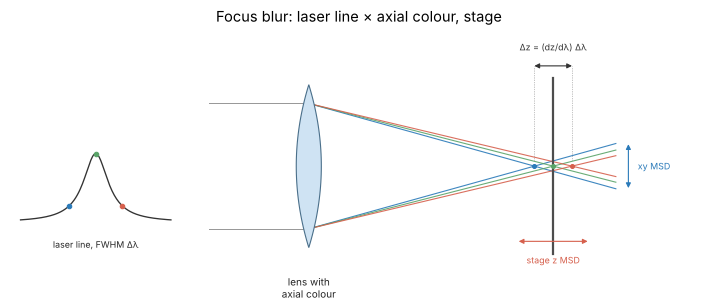

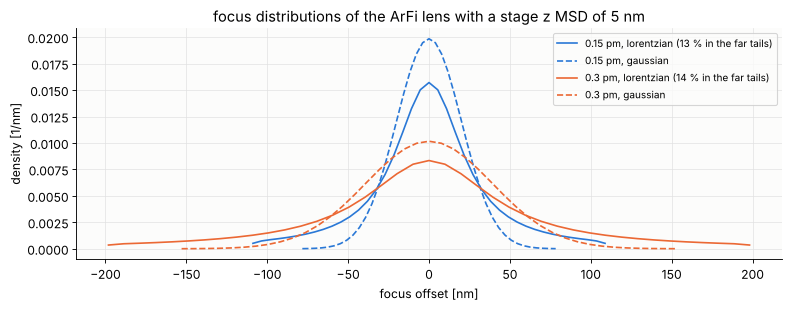

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
sketch.litho_stochastics_layout(ax, "focus_blur", title="Focus blur: laser line × axial colour, stage")
fig.tight_layout()

from pyoptics.raytrace import zeiss_arfi_lens
dz_krf = lens.axial_colour(caldwell_krf_lens())
dz_arf = lens.axial_colour(zeiss_arfi_lens())
print(f"axial colour: Caldwell KrF lens {dz_krf:.0f} nm per pm, Zeiss ArFi lens {dz_arf:.0f} nm per pm")
for fwhm in (0.15, 0.3, 0.6):
    print(f"  FWHM {fwhm} pm: ArFi focus FWHM {dz_arf*fwhm:.0f} nm, "
          f"E95 {focus_blur.e95(fwhm):.1f} pm (Lorentzian) / {focus_blur.e95(fwhm, 'gaussian'):.2f} pm (Gaussian)")
fig, ax = plt.subplots(figsize=(10, 4))
for fwhm, col in ((0.15, BLUE), (0.3, ORANGE)):
    for spec, ls in (("lorentzian", "-"), ("gaussian", "--")):
        B = focus_blur.FocusBlur(dz_arf, fwhm, spec, z_msd=5.0, n_foci=41)
        z, w, t = B.focus_distribution()
        ax.plot(z, w/(z[1] - z[0]), ls, color=col,
                label=f"{fwhm} pm, {spec}" + (f" ({100*t:.0f} % in the far tails)" if t > 0.001 else ""))
ax.set_xlabel("focus offset [nm]"); ax.set_ylabel("density [1/nm]"); ax.legend(fontsize=9)
ax.set_title("focus distributions of the ArFi lens with a stage z MSD of 5 nm")
fig.tight_layout()

At about 300 nm per pm, a bandwidth of 0.3 pm spreads the focus over 90 nm
FWHM, close to the whole depth of focus of a 50 nm line. Lenses without
colour correction need very narrow lasers, and scanners specify the
bandwidth both as FWHM and as E95, the width holding 95 % of the energy: a
Lorentzian line of the same FWHM puts much of its energy far out in the
tails (12.7 FWHM for 95 %), which a Gaussian does not (1.7 FWHM). Real
line-narrowed lasers lie in between, and FocusBlur also takes a measured
spectrum as offsets and weights.

The blurred images are the weighted sums of the images in all the focal
planes, computed in one batched call. Focus-exposure matrices of 50 nm lines
at a pitch of 130 nm (annular illumination, 6 % attenuated PSM) with
Gaussian lines of 0 to 0.5 pm FWHM and 5 nm z MSD:

0.0 pm: CD at best focus 50.0 nm, max EL 14.1 %, DOF at 5 % EL 140 nm
0.15 pm: CD at best focus 49.6 nm, max EL 13.8 %, DOF at 5 % EL 140 nm
0.3 pm: CD at best focus 48.5 nm, max EL 12.7 %, DOF at 5 % EL 140 nm
0.5 pm: CD at best focus 45.8 nm, max EL 10.7 %, DOF at 5 % EL 140 nm


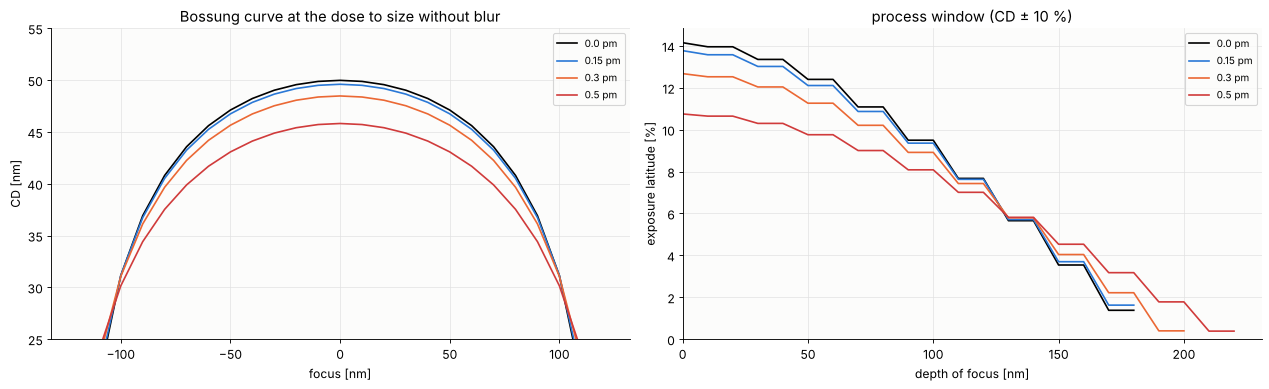

In [13]:
semi = LithoSimulation(MaskLayout.lines_spaces(130.0, 50.0), ThinMask.att_psm(),
                       Illumination.annular(0.9, 0.6, n_samples=15), proj)
x_k = np.arange(-65.0, 65.0, 0.5)
foci = np.linspace(-150, 150, 31)
dose_k = metrics.dose_to_size(x_k, semi.image(x_k), 50.0, threshold=0.3)
doses_k = dose_k*np.linspace(0.85, 1.2, 71)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for fwhm, col in ((0.0, "k"), (0.15, BLUE), (0.3, ORANGE), (0.5, RED)):
    B = focus_blur.FocusBlur(dz_arf, fwhm, "gaussian", z_msd=5.0)
    cd = metrics.fem_cd(x_k, B.through_focus(semi, x_k, foci), doses_k, threshold=0.3)
    axes[0].plot(foci, cd[np.argmin(np.abs(doses_k - dose_k))], color=col, label=f"{fwhm} pm")
    lo, hi = metrics.process_window(foci, doses_k, cd, 50.0, tolerance=0.1)
    dof, el = metrics.el_dof(foci, lo, hi)
    axes[1].plot(dof, 100*el, color=col, label=f"{fwhm} pm")
    print(f"{fwhm} pm: CD at best focus {cd[np.argmin(np.abs(doses_k - dose_k)), 15]:.1f} nm, "
          f"max EL {100*np.nanmax(el):.1f} %, DOF at 5 % EL {metrics.dof_at_el(dof, el, 0.05):.0f} nm")
axes[0].set_ylim(25, 55); axes[0].set_xlabel("focus [nm]"); axes[0].set_ylabel("CD [nm]")
axes[0].set_title("Bossung curve at the dose to size without blur"); axes[0].legend(fontsize=9)
axes[1].set_xlabel("depth of focus [nm]"); axes[1].set_ylabel("exposure latitude [%]")
axes[1].set_title("process window (CD ± 10 %)"); axes[1].set_xlim(0, None); axes[1].set_ylim(0, None)
axes[1].legend(fontsize=9)
fig.tight_layout()

The blur lowers the CD at best focus (the image there is already a mixture
of defocused images, so the dose to size moves) and takes exposure latitude
from the top of the process window: 0.5 pm costs about a quarter of the
maximum exposure latitude. At low exposure latitude the window even gets
a little deeper, because the blurred image at the edge of the window
borrows from planes closer to focus. Spreading the focus on purpose (a
broadened or multi-line laser spectrum, or a tilted scan, "focus
drilling") uses this for features with a very small depth of focus, such as
isolated contacts: it trades contrast for a longer process window.

## 8. Lateral stage vibration

The lateral moving standard deviation blurs the image with a Gaussian. It
acts on the image log slope directly: for the 45 nm ArF lines,

NILS 2.83 without, 2.77 at 3 nm and 2.42 at 8 nm MSD


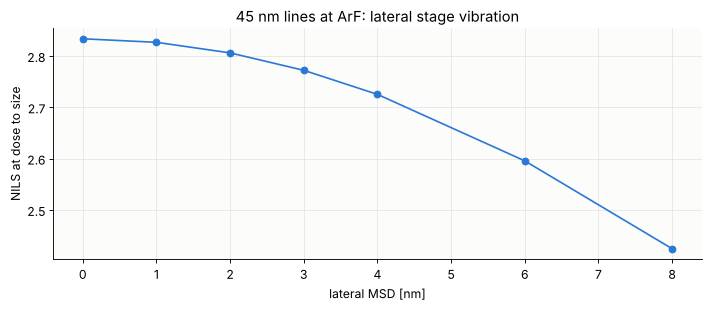

In [14]:
x_s = np.arange(-45.0, 45.0, 0.5)
I_s0 = lines.image(x_s)
msd = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 6.0, 8.0])
nils_s = [metrics.nils_at_threshold(x_s, D*focus_blur.FocusBlur(xy_msd=m).blur_xy(I_s0, 0.5), 0.3)
          for m, D in [(m, metrics.dose_to_size(x_s, focus_blur.FocusBlur(xy_msd=m).blur_xy(I_s0, 0.5), 45.0))
                       for m in msd]]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(msd, nils_s, "o-", color=BLUE)
ax.set_xlabel("lateral MSD [nm]"); ax.set_ylabel("NILS at dose to size")
ax.set_title("45 nm lines at ArF: lateral stage vibration")
fig.tight_layout()
print(f"NILS {nils_s[0]:.2f} without, {nils_s[3]:.2f} at 3 nm and {nils_s[-1]:.2f} at 8 nm MSD")

Up to 3 nm of MSD cost only 2 % of the NILS of a 45 nm line, 8 nm cost
15 %, and the loss feeds straight back into the stochastics of section 3: a flatter
image gives rougher edges. Stage MSD, laser bandwidth, flare and the resist
chemistry therefore all end up in the same LER and LCDU budget.

## Summary

- `litho.stochastics.StochasticResist` runs the resist chain of
  `resist.ResistModel` with Poisson photons, acid, quencher and protecting
  groups on a top-down grid; the wavelength sets the photon energy.
  `line_edges()`, `roughness()`, `edge_psd()`, `fit_psd()`, `random_edges()`
  and `contact_stats()` turn the developed resist into LER, LWR, PSD
  parameters, local CDU and missing or merged holes.
- At ArF the chemistry (acid and quencher counts) dominates the roughness of
  45 nm lines; the same resist with 13.5 nm photons is photon limited.
- `litho.flare.Flare` holds a power-law PSF or one derived from a roughness
  PSD (`ABCRoughness`, `tis()`, scatter $\propto 1/\lambda^2$), and gives the
  flare level for a density or a whole die (`level_map()`).
- `litho.focus_blur.FocusBlur` averages images over the focus spread of the
  laser line times the axial colour (`lens.axial_colour()`: 241 nm per pm for
  Caldwell's KrF lens, 306 nm per pm for the Zeiss ArFi lens) and the stage z
  MSD, and blurs them with the xy MSD.

The EUV notebooks will reuse all of this with 13.5 nm photons, mirror
scatter and the EUV resist.

In [15]:
print(f"run time {time.time() - t_start:.0f} s")

run time 50 s
